# Stock 8: a hidden file, a hidden team effect, and an extreme test row

Stock 8 has three things to discover:
1. a **hidden file** (`Copy of export.csv`) with two extra clues, `m1` and `m2`, that turn out to drive the price
2. a **team effect** between `x2` and `x3` that no single correlation shows
3. a **test row that is extreme on every x clue**, so most models have to guess far outside their data

The goal is to find the **true formula** behind the price, not just the lowest score.

### The plan

| Part | What we do |
|---|---|
| 1 | Load the data and join the hidden file |
| 2 | Look at the data and the test row |
| 3 | Find the formula: search for team effects, curves, ratios and thresholds |
| 4 | Test 11 models, including an **extrapolation stress test** |
| 5 | Look inside the final model |
| 6 | Measure how sure we are, and what happens if the formula bends |
| 7 | Make a quote and a trading plan |

### Words used in this notebook

| Word | Meaning |
|---|---|
| **Clue** (= feature) | One column used to predict the price: `x1`–`x12`, plus `m1`, `m2` from the hidden file. |
| **Leftover** | Real price minus what a model predicts: the part the model hasn't explained. |
| **Team effect** (= interaction) | Two clues that change the price **together**, e.g. through `x2 × x3`. |
| **Extrapolate** | Predict outside the range of the training data. |
| **Stress test** | Train only on central rows, then check how well a model predicts the outer rows. |
| **CV RMSE** | How many pounds a model is wrong by on rows it hasn't seen. Smaller is better. |

---
# Part 1: Load the data and join the hidden file

### Step 1.1: Load the tools

**What this cell does:** loads the libraries. New this time: `curve_fit` (fits any formula you write yourself) and `combinations` / `permutations` (to loop over every pair of clues).

In [1]:
import warnings
warnings.filterwarnings("ignore")          # hide harmless library warnings so the output stays readable

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import combinations, permutations
from scipy import stats
from scipy.optimize import curve_fit

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, cross_val_predict
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

print("All tools loaded.")

All tools loaded.


### Step 1.2: Open the three files

**What this cell does:** reads the training file, the test file, and the hidden file `Copy of export.csv`, which has `uid`, `m1` and `m2`.

In [2]:
DATA_DIR = Path("../datasets")     # the data folder is one level up from this notebook
if not DATA_DIR.exists():          # in case the notebook was started from the main folder instead
    DATA_DIR = Path("datasets")

train = pd.read_csv(DATA_DIR / "stock_8_train.csv")
test = pd.read_csv(DATA_DIR / "stock_8_test.csv")
export = pd.read_csv(DATA_DIR / "Copy of export.csv")      # the hidden file

xs = [c for c in train.columns if c.startswith("x")]        # x1 ... x12
print("Training rows:", len(train), "   Test rows:", len(test), "   Hidden-file rows:", len(export))
display(export.head())
test

Training rows: 15000    Test rows: 1    Hidden-file rows: 14401


,uid,m1,m2
0,fc76812b57,-0.8916,0.7610
1,232ad9c587,-0.3487,1.3965
2,95f5edd2d7,0.1760,0.5298
3,4a5051218d,-0.1321,-0.8959
4,8e8afd9c76,1.4234,-0.6789


,id,uid,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12
0,stock_8,2df8f310dd,4.8605,-4.9409,-4.7694,4.7351,4.9294,4.3117,4.9683,-4.7736,-4.3345,4.1312,4.5303,-4.4427


**How to read the output:** 15,000 training rows with 12 clues. The hidden file has 14,401 rows, each with a `uid` (the row's ID) and two numbers, `m1` and `m2`.

Look at the test row: **every x clue is about ±4 to ±5**. Keep that in mind.

### Step 1.3: Join the hidden file to the data

`uid` is the same ID in all three files, so we can attach `m1` and `m2` to each row by matching `uid`. A **left join** keeps every training row, and leaves `m1`/`m2` empty where the hidden file has no match.

**What this cell does:** joins the files and counts the matches.

In [3]:
train_all = train.merge(export, on="uid", how="left")       # keep every training row, attach m1/m2 where the uid matches
test = test.merge(export, on="uid", how="left")

has_m = train_all["m1"].notna()
print(f"Training rows with m1/m2:    {has_m.sum():,}")
print(f"Training rows without m1/m2: {(~has_m).sum():,}")
print(f"Test row found in the hidden file: {test['m1'].notna().all()}")
print(f"Hidden-file rows that match neither file: {(~export['uid'].isin(train['uid']) & ~export['uid'].isin(test['uid'])).sum()}")
test[["uid", "m1", "m2"]]

Training rows with m1/m2:    14,400
Training rows without m1/m2: 600
Test row found in the hidden file: True
Hidden-file rows that match neither file: 0


,uid,m1,m2
0,2df8f310dd,1.4467,-1.0977


**How to read the output:** 14,400 of the 15,000 training rows get `m1`/`m2`, and so does the **test row** (m1 = 1.45, m2 = −1.10). 600 training rows have no match. Every row in the hidden file belongs to stock 8.

### Step 1.4: Health check

**What this cell does:** counts empty cells and repeated rows, and summarises the price.

In [4]:
clues = xs + ["m1", "m2"]
print("Empty cells in train, per column (only non-zero shown):")
print(train_all[clues].isna().sum()[lambda s: s > 0].to_string())
print("Repeated rows:", train_all[xs].duplicated().sum())
train_all["price"].describe().round(2)

Empty cells in train, per column (only non-zero shown):
m1    600
m2    600
Repeated rows: 0


count    15000.00
mean        79.92
std         11.01
min         32.86
25%         72.45
50%         79.87
75%         87.29
max        124.20
Name: price, dtype: float64

**How to read the output:** the only empty cells are the 600 missing `m1`/`m2` values. Prices average about **£80**, with a spread of about £11, and the highest is about **£124**.

> **✅ Checkpoint.** Three files joined by `uid`. 600 training rows have no `m1`/`m2`. The test row has them.

---
# Part 2: Look at the data

### Step 2.1: Is the test row normal?

**What this cell does:** puts each test value next to the training range, then measures how far the test row is from the centre using all 12 x clues together (the square root of the sum of squares, like a distance on a map).

In [5]:
test_row = test[clues].iloc[0]
check = pd.DataFrame({"test value": test_row,
                      "training min": train_all[clues].min(),
                      "training max": train_all[clues].max()})
check["inside range?"] = (check["test value"] >= check["training min"]) & (check["test value"] <= check["training max"])
display(check.round(2))

distance_train = np.sqrt((train_all[xs] ** 2).sum(axis=1))
distance_test = float(np.sqrt((test[xs] ** 2).sum(axis=1)).iloc[0])
print(f"Distance from the centre (12 x clues): furthest training row {distance_train.max():.1f}, test row {distance_test:.1f}")

,test value,training min,training max,inside range?
x1,4.86,-4.07,4.04,False
x2,-4.94,-4.48,4.38,False
x3,-4.77,-3.97,4.19,False
x4,4.74,-3.97,3.98,False
x5,4.93,-3.60,4.28,False
x6,4.31,-3.70,4.00,False
x7,4.97,-4.05,4.12,False
x8,-4.77,-4.04,3.77,False
x9,-4.33,-3.94,4.34,False
x10,4.13,-3.94,3.55,False


Distance from the centre (12 x clues): furthest training row 6.1, test row 16.1


**How to read the output**

* **All 12 x clues** of the test row are outside the training range.
* `m1` and `m2` are inside, and normal.
* Counting all 12 x clues together, the test row is about **16** from the centre. The furthest training row is about **6**.

So **any model that uses the x clues has to guess far outside its data**. Whether that matters depends on which clues actually move the price.

### Step 2.2: Which clues move the price?

**What this cell does:** keeps the 14,400 rows that have `m1`/`m2`, and shows each clue's correlation with the price, and the largest correlation between any two clues.

In [6]:
data = train_all[has_m].reset_index(drop=True)      # the 14,400 rows with m1/m2
y = data["price"]

display(data[clues].corrwith(y).round(3).to_frame("correlation with price").T)
between = np.abs(data[clues].corr().values[np.triu_indices(len(clues), 1)])
print(f"Largest correlation between two clues: {between.max():.3f}")

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,m1,m2
correlation with price,0.173,0.004,0.002,0.087,0.01,-0.004,0.002,-0.003,-0.004,-0.004,0.003,-0.004,0.732,-0.45


Largest correlation between two clues: 0.029


**How to read the output**

* **m1 (+0.73)** and **m2 (−0.45)** are by far the strongest. They come from the hidden file, so **teams that miss it lose most of the information**.
* **x1 (+0.17)** and **x4 (+0.09)** matter a little.
* The other 10 x clues show about 0. But correlation only sees straight lines and single clues, so Part 3 searches properly.
* The clues are unrelated to each other (largest correlation about 0.03).

### Step 2.3: The shape of each clue's effect

**What this cell does:** for each of the 14 clues, cuts it into 10 slices and draws the average price per slice. The dashed line is the test row's value (often off the chart).

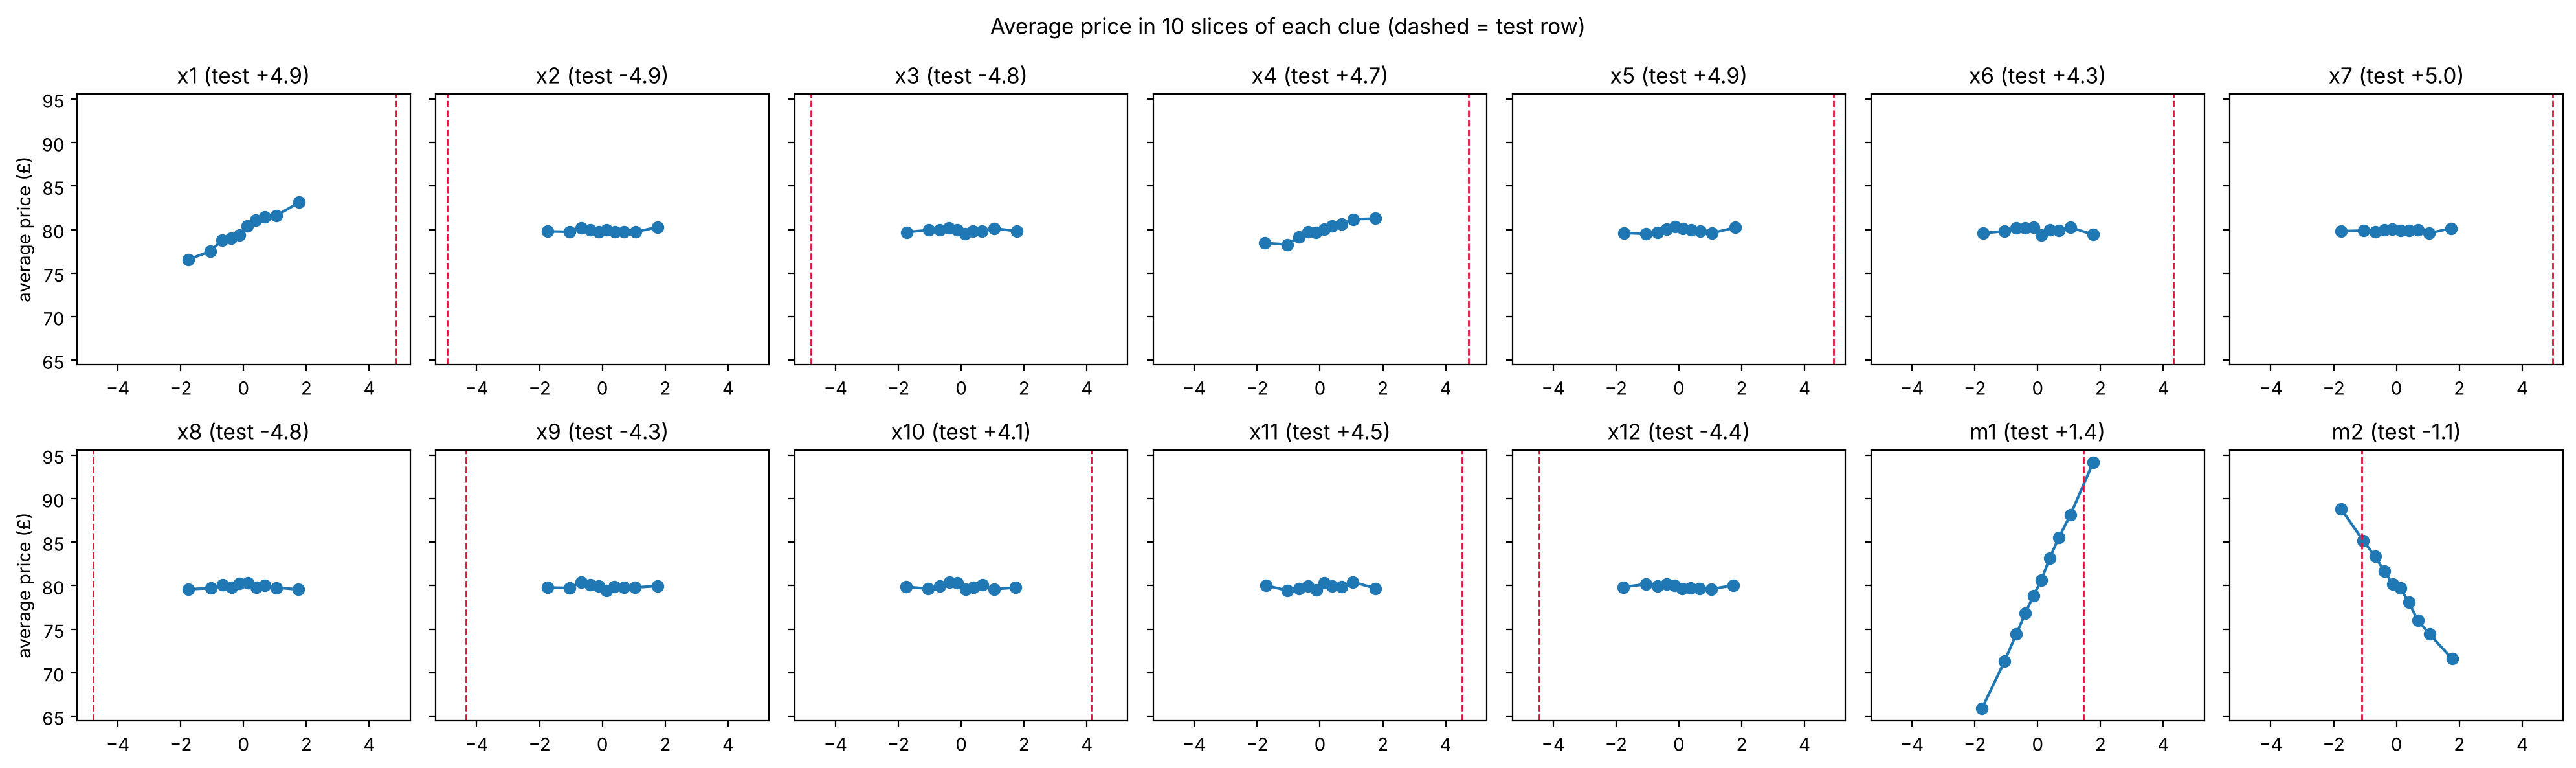

In [7]:
fig, axes = plt.subplots(2, 7, figsize=(20, 6), sharey=True)
for ax, clue in zip(axes.ravel(), clues):
    slices = pd.qcut(data[clue], 10)
    ax.plot(data[clue].groupby(slices, observed=True).mean(), y.groupby(slices, observed=True).mean(), marker="o")
    ax.axvline(test_row[clue], color="crimson", linestyle="--", linewidth=1)
    ax.set_xlim(-5.3, 5.3)
    ax.set_title(f"{clue} (test {test_row[clue]:+.1f})")
axes[0, 0].set_ylabel("average price (£)"); axes[1, 0].set_ylabel("average price (£)")
fig.suptitle("Average price in 10 slices of each clue (dashed = test row)")
plt.tight_layout()
plt.show()

**How to read the output:** `m1` goes up steeply, `m2` goes down, `x1` and `x4` go up gently. Every other clue is flat. All lines look straight.

Notice the dashed lines for the x clues: they sit **beyond the end** of every blue line. The models have no data there.

> **✅ Checkpoint.** The main drivers are `m1`, `m2` (from the hidden file), `x1` and `x4`. The test row is extreme on all x clues.

---
# Part 3: Find the formula

### Step 3.1: A first straight line

**What this cell does:** fits a straight line on the 4 clues that clearly matter, and keeps the **leftover** (real price minus predicted) for the search in Step 3.2.

In [8]:
first_clues = ["m1", "m2", "x1", "x4"]
first_line = LinearRegression().fit(data[first_clues], y)
leftover = y - first_line.predict(data[first_clues])

print("price ≈ {:.2f}".format(first_line.intercept_) +
      "".join(f" {w:+.2f}·{c}" for c, w in zip(first_clues, first_line.coef_)))
print(f"Leftover std: £{leftover.std():.2f}")

price ≈ 79.95 +8.02·m1 -4.90·m2 +2.03·x1 +0.95·x4
Leftover std: £5.20


**How to read the output:** price ≈ 80 + 8·m1 − 4.9·m2 + 2·x1 + 0.95·x4, with about £5.20 left unexplained.

### Step 3.2: Search the leftover for anything hidden

If something else drives the price, it must be in the leftover. **What this cell does:** tests hundreds of candidates and measures each one's correlation with the leftover:

| Type | What it tests | Example |
|---|---|---|
| Product | two clues as a team | x2 × x3 |
| Shape | a curve of one clue | x5², \|x5\|, x5³, sign, sine, tanh |
| Ratio | one clue divided by another | x2 / x3 |
| Threshold | a sudden jump at a cut-off | "x5 > 1" |
| Conditional | a clue that only works when another is positive | "x1 only when x6 > 0" |

With hundreds of tries, some correlations will be a little above 0 **by pure chance**. The cell also prints how big that chance level is.

In [9]:
def corr_with_leftover(values):
    return np.corrcoef(leftover, values)[0, 1]

found = []
for a, b in combinations(clues, 2):
    found.append(("product", f"{a} × {b}", corr_with_leftover(data[a] * data[b])))

curves = {"square": lambda v: v ** 2, "absolute": np.abs, "cube": lambda v: v ** 3,
          "sign": np.sign, "sine": np.sin, "tanh": np.tanh}
for c in clues:
    for name, fn in curves.items():
        found.append(("shape", f"{name}({c})", corr_with_leftover(fn(data[c]))))

for a, b in permutations(clues, 2):
    ratio = data[a] / data[b]
    ratio = ratio.clip(ratio.quantile(0.01), ratio.quantile(0.99))   # tame huge values when the bottom is near 0
    found.append(("ratio", f"{a} / {b}", corr_with_leftover(ratio)))

for c in clues:
    for cut in [-2, -1, 0, 1, 2]:
        found.append(("threshold", f"{c} > {cut}", corr_with_leftover((data[c] > cut).astype(float))))

for a in first_clues:
    for b in clues:
        if b != a:
            found.append(("conditional", f"{a} only when {b} > 0", corr_with_leftover(data[a] * (data[b] > 0))))

search = pd.DataFrame(found, columns=["type", "candidate", "correlation with leftover"])
search = search.reindex(search["correlation with leftover"].abs().sort_values(ascending=False).index).reset_index(drop=True)
chance = np.sqrt(2 * np.log(len(search))) / np.sqrt(len(data))     # roughly the biggest value pure chance gives
print(f"Candidates tested: {len(search)}.  Biggest correlation expected by pure chance: about {chance:.3f}")
search.head(10).round(3)

Candidates tested: 479.  Biggest correlation expected by pure chance: about 0.029


,type,candidate,correlation with leftover
0,product,x2 × x3,0.286
1,ratio,x2 / x3,0.055
2,ratio,x3 / x2,0.043
3,product,x6 × x8,0.025
4,ratio,x10 / x8,-0.022
5,ratio,m2 / x1,-0.022
6,product,x4 × x12,0.021
7,ratio,x9 / x10,-0.021
8,threshold,x5 > 1,0.021
9,ratio,x9 / x11,0.021


**How to read the output**

* **x2 × x3** has a correlation of about **0.29** with the leftover, roughly 10 times the chance level.
* Next come **x2 / x3** and **x3 / x2** (about 0.04–0.05). They're just echoes of x2 × x3: a ratio and a product of the same two clues always have the same sign.
* Everything else is at or below the chance level (about 0.03). No thresholds, no curves, no conditional effects, no other teams.

**What this cell does:** draws the top 12 candidates next to the chance level.

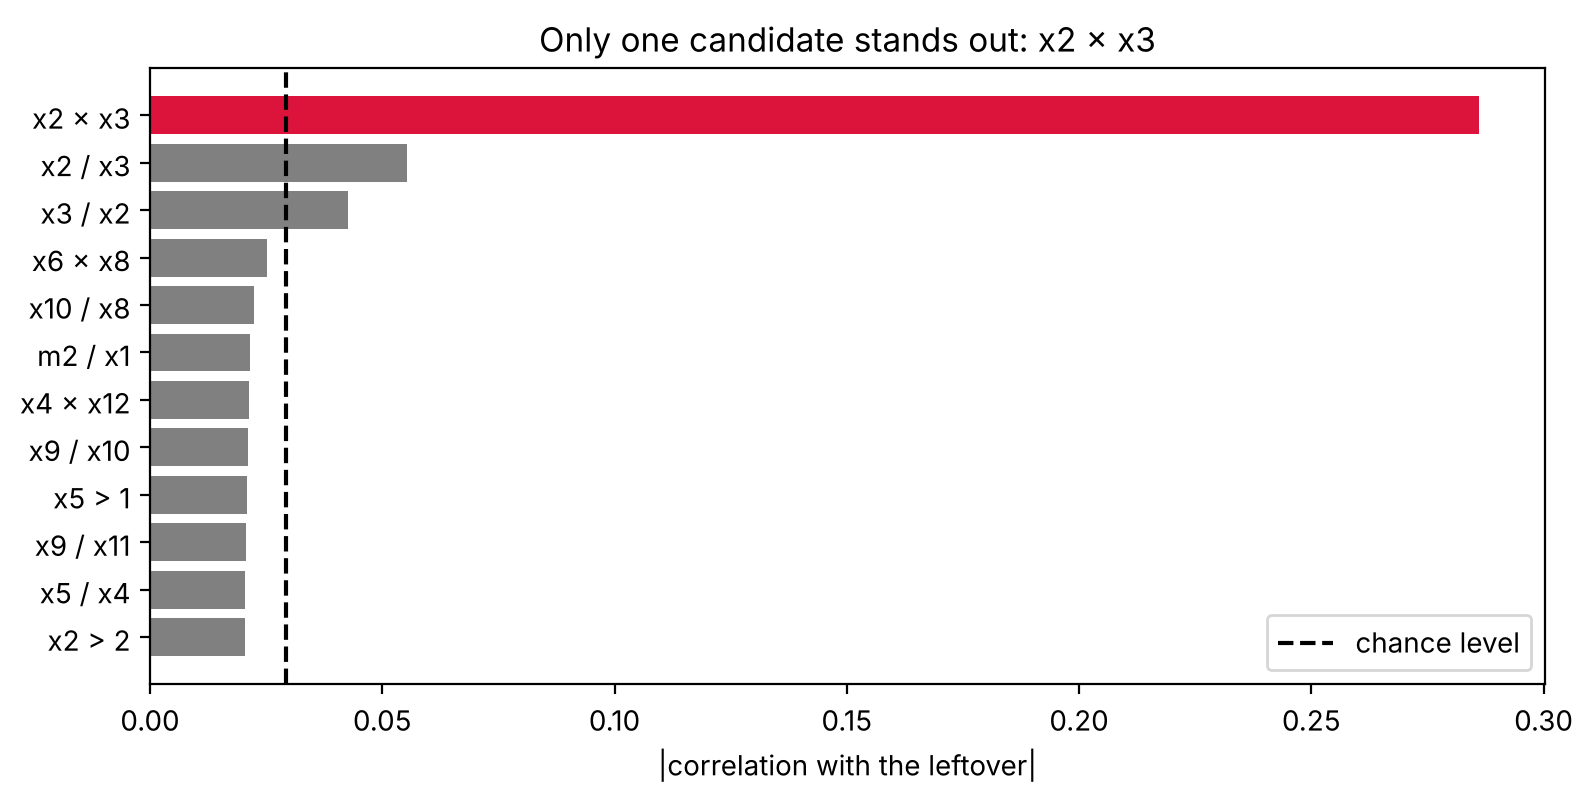

In [10]:
top = search.head(12)
plt.figure(figsize=(9, 4))
plt.barh(top["candidate"], top["correlation with leftover"].abs(),
         color=["crimson" if v > 3 * chance else "grey" for v in top["correlation with leftover"].abs()])
plt.axvline(chance, color="black", linestyle="--", label="chance level")
plt.gca().invert_yaxis()
plt.xlabel("|correlation with the leftover|")
plt.title("Only one candidate stands out: x2 × x3")
plt.legend()
plt.show()

### Step 3.3: See the team effect

**What this cell does:** draws the average leftover for 5 slices of x2 against 5 slices of x3.

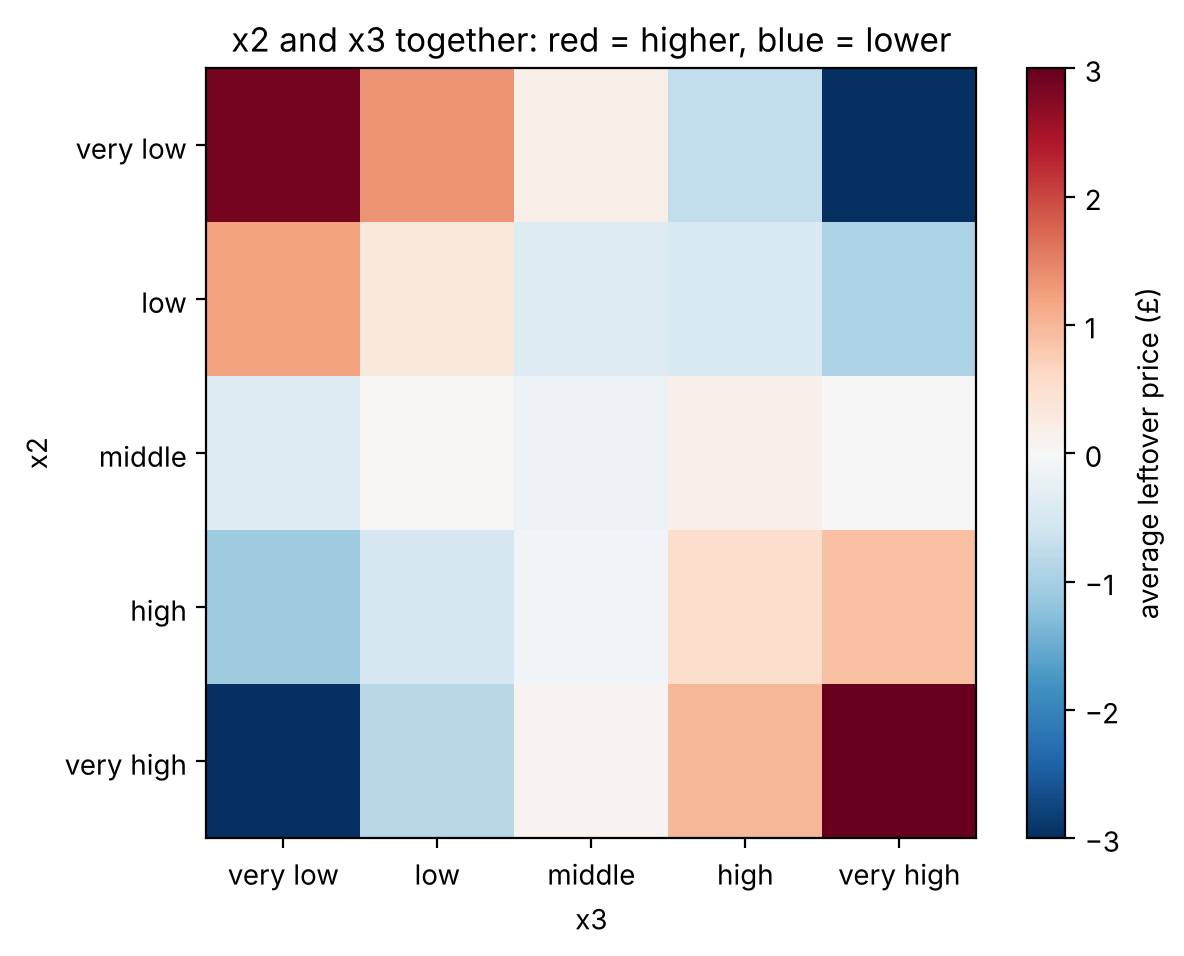

In [11]:
labels = ["very low", "low", "middle", "high", "very high"]
x2_slice = pd.qcut(data["x2"], 5, labels=labels)
x3_slice = pd.qcut(data["x3"], 5, labels=labels)
grid = leftover.groupby([x2_slice, x3_slice], observed=True).mean().unstack()

plt.figure(figsize=(6.5, 5))
plt.imshow(grid.values, cmap="RdBu_r", vmin=-3, vmax=3)
plt.colorbar(label="average leftover price (£)")
plt.xticks(range(5), grid.columns); plt.yticks(range(5), grid.index)
plt.xlabel("x3"); plt.ylabel("x2")
plt.title("x2 and x3 together: red = higher, blue = lower")
plt.show()

**How to read the output:** red in two corners (both high, or both low), blue in the other two (one high, one low). That's the pattern of **x2 × x3**: same sign pushes the price up, opposite signs push it down.

**For the test row, x2 = −4.94 and x3 = −4.77: both very low, so x2 × x3 = +23.6.** In training, x2 × x3 never goes above about 6.9.

### Step 3.4: The formula with the team effect

**What this cell does:** adds x2 × x3 to the line, and shows each weight with its **standard error** (how precisely it's measured).

In [12]:
def formula_clues(d):
    # the 5 ingredients of the formula
    return pd.DataFrame({"m1": d["m1"], "m2": d["m2"], "x1": d["x1"], "x4": d["x4"], "x2_times_x3": d["x2"] * d["x3"]})

F = formula_clues(data)
formula = LinearRegression().fit(F, y)
formula_leftover = y - formula.predict(F)

# standard errors of the weights (how precisely each one is measured)
design = np.column_stack([np.ones(len(F)), F.values])
cov = np.linalg.inv(design.T @ design) * formula_leftover.var(ddof=design.shape[1])
std_err = np.sqrt(np.diag(cov))

weights_table = pd.DataFrame({"weight": np.r_[formula.intercept_, formula.coef_], "± (standard error)": std_err},
                             index=["start"] + list(F.columns)).round(3)
display(weights_table)
print(f"Leftover std: £{formula_leftover.std():.3f}")

x2x3_train = data["x2"] * data["x3"]
x2x3_test = float((test["x2"] * test["x3"]).iloc[0])
print(f"x2 × x3 in training: {x2x3_train.min():.2f} to {x2x3_train.max():.2f}     test row: {x2x3_test:.2f}")

,weight,± (standard error)
start,79.939,0.042
m1,8.024,0.041
m2,-4.897,0.041
x1,2.021,0.041
x4,0.964,0.041
x2_times_x3,1.502,0.042


Leftover std: £4.984
x2 × x3 in training: -8.43 to 6.87     test row: 23.57


**How to read the output**

* **price ≈ 80 + 8·m1 − 4.9·m2 + 2·x1 + 0.96·x4 + 1.5·(x2 × x3)**
* Each weight is measured to within about ±0.04, and they sit very close to **round numbers** (80, 8, −5, 2, 1, 1.5). That's a strong sign this is the organisers' recipe.
* The leftover shrinks to about **£4.99**.

### Step 3.5: Straight line or curve?

The test row needs x2 × x3 = 23.6, but training only reaches about 7. So it matters whether these effects stay **straight** or **bend**. **What this cell does:**
1. adds a squared or cubed version of each ingredient and checks if it helps (**p-value**: below 0.05 means "a real curve")
2. tries other shapes for the team effect and compares the leftover

In [13]:
curve_rows = []
base = formula_clues(data)
for name in ["m1", "m2", "x1", "x4", "x2_times_x3"]:
    for power in [2, 3]:
        extra = base.copy()
        extra["curve"] = base[name] ** power
        X_ = np.column_stack([np.ones(len(extra)), extra.values])
        coef, *_ = np.linalg.lstsq(X_, y, rcond=None)
        resid = y - X_ @ coef
        se = np.sqrt(np.linalg.inv(X_.T @ X_)[-1, -1] * resid.var(ddof=X_.shape[1]))
        p = 2 * stats.norm.sf(abs(coef[-1] / se))
        curve_rows.append({"added": f"{name}^{power}", "p-value": round(p, 3)})
display(pd.DataFrame(curve_rows).set_index("added").T)

shapes_to_try = {
    "x2 × x3 (product)": data["x2"] * data["x3"],
    "x2 × x3, capped at ±3": (data["x2"] * data["x3"]).clip(-3, 3),
    "tanh(x2) × tanh(x3)": np.tanh(data["x2"]) * np.tanh(data["x3"]),
    "sign × √|x2 × x3|": np.sign(data["x2"] * data["x3"]) * np.sqrt(np.abs(data["x2"] * data["x3"])),
    "sign(x2 × x3) only": np.sign(data["x2"] * data["x3"]),
}
rows = []
for name, team in shapes_to_try.items():
    X_ = data[first_clues].assign(team=team)
    rows.append({"team-effect shape": name, "leftover std (£)": (y - LinearRegression().fit(X_, y).predict(X_)).std()})
pd.DataFrame(rows).round(4)

added,m1^2,m1^3,m2^2,m2^3,x1^2,x1^3,x4^2,x4^3,x2_times_x3^2,x2_times_x3^3
p-value,0.514,0.231,0.042,0.914,0.805,0.521,0.402,0.514,0.852,0.342


,team-effect shape,leftover std (£)
0,x2 × x3 (product),4.9843
1,"x2 × x3, capped at ±3",4.9884
2,tanh(x2) × tanh(x3),5.0125
3,sign × √|x2 × x3|,5.0143
4,sign(x2 × x3) only,5.1105


**How to read the output**

* **None of the curves really helps.** Only m2² dips just under 0.05 (p ≈ 0.04). With 10 tries, one result that low is expected by chance, and its effect is tiny: about 7p at the test row, where it leaves the price at £146.70. Every effect is a straight line, as far as the data goes.
* The plain **product x2 × x3** gives the smallest leftover. Shapes that level off early (capped at ±3, tanh × tanh, square root) are all worse.

So **inside the training range**, the formula is straight lines plus x2 × x3. Part 6 asks what happens **beyond** it.

### Step 3.6: Is the leftover pure noise?

**What this cell does:** checks the leftover's shape (is it a bell?), and whether its size changes far from the centre.

In [14]:
r = formula_leftover
print(f"Leftover std £{r.std():.2f}    skew {stats.skew(r):+.3f}    bell-shape test p-value {stats.normaltest(r).pvalue:.2f}")
for k in [1, 2, 3]:
    print(f"within ±{k} std: {(r.abs() < k * r.std()).mean():.1%}   (bell shape: {[68.3, 95.4, 99.7][k-1]}%)")
far = pd.qcut(np.sqrt((data[xs] ** 2).sum(axis=1)), 5, labels=["closest", "close", "middle", "far", "furthest"])
print("\nLeftover std by distance from the centre:", r.groupby(far, observed=True).std().round(2).to_dict())

Leftover std £4.98    skew +0.006    bell-shape test p-value 0.59
within ±1 std: 68.5%   (bell shape: 68.3%)
within ±2 std: 95.6%   (bell shape: 95.4%)
within ±3 std: 99.7%   (bell shape: 99.7%)

Leftover std by distance from the centre: {'closest': 4.96, 'close': 5.04, 'middle': 4.95, 'far': 5.01, 'furthest': 4.96}


**How to read the output:** the leftover is a clean **bell curve** (68% within 1 std, 95% within 2), with a std of about **£5**. Its size is the **same** near and far from the centre. There's nothing left to model.

### Step 3.7: Do the 600 rows without m1/m2 follow the same rules?

**What this cell does:** fits the x part of the formula on the 600 rows without m1/m2. If they're just randomly missing, the x weights should match, and the leftover should be bigger by exactly the missing m1/m2 part.

In [15]:
no_m = train_all[~has_m]
Xn = pd.DataFrame({"x1": no_m["x1"], "x4": no_m["x4"], "x2_times_x3": no_m["x2"] * no_m["x3"]})
x_only = LinearRegression().fit(Xn, no_m["price"])
print("600 rows without m1/m2:", dict(zip(Xn.columns, x_only.coef_.round(2))))
print(f"Their leftover std: £{(no_m['price'] - x_only.predict(Xn)).std():.2f}")
print(f"Expected if m1/m2 are simply missing: £{np.sqrt(r.var() + (formula.coef_[0] ** 2) * data['m1'].var() + (formula.coef_[1] ** 2) * data['m2'].var()):.2f}")

600 rows without m1/m2: {'x1': np.float64(1.35), 'x4': np.float64(1.83), 'x2_times_x3': np.float64(1.49)}
Their leftover std: £10.34
Expected if m1/m2 are simply missing: £10.69


**How to read the output:** x2 × x3 matches almost exactly (1.49 against 1.50). x1 and x4 are within about 2 standard errors of the main formula (with only 600 rows, each of these weights is only known to about ±0.4), and the leftover is about as big as expected. So the hidden file is **missing at random** for these rows, and leaving them out is safe.

> **✅ Checkpoint. The formula:**
> **price = 80 + 8·m1 − 5·m2 + 2·x1 + 1·x4 + 1.5·(x2 × x3) + bell-shaped noise (std £5)**
> x5–x12 do nothing. The test row is extreme on exactly the clues that matter (x1, x4, x2 × x3) **and** on the decoys (x5–x12).

---
# Part 4: Test 11 models

### Step 4.1: The fair-test setup and the stress test

Normal cross-validation only tests rows **like** the training data. Our test row is far outside. So we add a **stress test**:

1. train each model only on **central rows** (|x2 × x3| < 1.5, |x1| < 2, |x4| < 2)
2. predict the **outer rows** (|x2 × x3| > 3), which the model has never seen anything like
3. measure the average miss (**bias**) on each side. A model that extrapolates correctly has a bias of about 0.

**What this cell does:** sets up the data, the 5-fold cross-validation and the two groups of rows.

In [16]:
X = data[clues]
X_test = test[clues]
cv = KFold(n_splits=5, shuffle=True, random_state=0)

central = (x2x3_train.abs() < 1.5) & (data["x1"].abs() < 2) & (data["x4"].abs() < 2)
outer = x2x3_train.abs() > 3
outer_positive = x2x3_train[outer] > 0
print(f"Central rows (for stress-test training): {central.sum():,}    Outer rows (stress-test checking): {outer.sum()}")

Central rows (for stress-test training): 11,705    Outer rows (stress-test checking): 278


### Step 4.2: The 11 models

| Family | Model | How it works, in one line |
|---|---|---|
| Straight line | Linear regression | Best straight line through all 14 clues (no team effect) |
| **Formula** | **Linear + x2 × x3** | Our formula from Part 3 |
| Curves | Polynomial + Ridge | Every square and pair product of all 14 clues, shrunk |
| Curves | Polynomial + Lasso | The same, but useless terms are pushed to exactly 0 |
| Distance | KNN | Averages the prices of the most similar rows |
| Trees | Random forest, HistGB, XGBoost, LightGBM | Many decision trees |
| Trees | LightGBM + x2 × x3 column | LightGBM, also given the product as a ready-made clue |
| Neural network | MLP | Layers of "neurons" |

**What this cell does:** lists each model with the settings to try.

In [17]:
def add_product(d):
    # all clues, plus x2 × x3 as an extra ready-made column
    out = d.copy()
    out["x2_times_x3"] = d["x2"] * d["x3"]
    return out

boost_settings = {"model__n_estimators": [300, 600, 1000], "model__learning_rate": [0.03, 0.05, 0.1],
                  "model__subsample": [0.8, 1.0], "model__colsample_bytree": [0.5, 0.8, 1.0]}

grid_models = {
    "Linear regression": (Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]), {}),
    "Formula: linear + x2×x3": (Pipeline([("formula", FunctionTransformer(formula_clues)), ("model", LinearRegression())]), {}),
    "Polynomial + Ridge": (Pipeline([("poly", PolynomialFeatures(2)), ("scaler", StandardScaler()), ("model", Ridge())]),
                           {"model__alpha": [1, 100]}),
    "Polynomial + Lasso": (Pipeline([("poly", PolynomialFeatures(2)), ("scaler", StandardScaler()), ("model", Lasso(max_iter=5000))]),
                           {"model__alpha": [0.01, 0.05, 0.2]}),
    "KNN": (Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor())]), {"model__n_neighbors": [10, 30]}),
    "Random forest": (Pipeline([("model", RandomForestRegressor(n_estimators=100, max_features=0.5, random_state=0, n_jobs=1))]),
                      {"model__min_samples_leaf": [5, 20]}),
    "HistGB": (Pipeline([("model", HistGradientBoostingRegressor(max_iter=500, random_state=0))]),
               {"model__max_depth": [3, None], "model__learning_rate": [0.05, 0.1]}),
    "Neural network (MLP)": (Pipeline([("scaler", StandardScaler()), ("model", MLPRegressor(max_iter=300, early_stopping=True, random_state=0))]),
                             {"model__hidden_layer_sizes": [(64, 64), (128, 64)], "model__alpha": [0.0001, 0.01]}),
}
random_models = {
    "XGBoost": (Pipeline([("model", XGBRegressor(random_state=0, n_jobs=1))]),
                {**boost_settings, "model__max_depth": [3, 4, 6], "model__min_child_weight": [1, 10]}),
    "LightGBM": (Pipeline([("model", LGBMRegressor(random_state=0, n_jobs=1, subsample_freq=1, verbose=-1))]),
                 {**boost_settings, "model__num_leaves": [7, 15, 31], "model__min_child_samples": [20, 50]}),
    "LightGBM + x2×x3 column": (Pipeline([("add", FunctionTransformer(add_product)),
                                          ("model", LGBMRegressor(random_state=0, n_jobs=1, subsample_freq=1, verbose=-1))]),
                                {**boost_settings, "model__num_leaves": [7, 15, 31], "model__min_child_samples": [20, 50]}),
}
print("Models ready:", list(grid_models) + list(random_models))

Models ready: ['Linear regression', 'Formula: linear + x2×x3', 'Polynomial + Ridge', 'Polynomial + Lasso', 'KNN', 'Random forest', 'HistGB', 'Neural network (MLP)', 'XGBoost', 'LightGBM', 'LightGBM + x2×x3 column']


### Step 4.3: Run the contest

**What this cell does:** for each model, it
1. tries the settings with 5-fold cross-validation and keeps the best (8 random combinations for the boosting models)
2. runs the **stress test**: the same model and settings, trained on central rows only, then scored on the outer rows
3. prices the test row

It takes a few minutes.

In [18]:
results, searches = [], {}

def record(name, search):
    searches[name] = search
    stressed = clone(search.best_estimator_).fit(X[central], y[central])         # trained on central rows only
    miss = y[outer].values - np.ravel(stressed.predict(X[outer]))                # misses on the outer rows
    results.append({
        "model": name,
        "CV RMSE (£)": round(-search.best_score_, 3),
        "stress: bias when x2×x3 > 3 (£)": round(float(miss[outer_positive.values].mean()), 2),
        "stress: bias when x2×x3 < −3 (£)": round(float(miss[~outer_positive.values].mean()), 2),
        "test price (£)": round(float(np.ravel(search.predict(X_test))[0]), 2),
    })
    print(f"{name} done")

for name, (pipe, settings) in grid_models.items():
    search = GridSearchCV(pipe, settings, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    record(name, search.fit(X, y))

for name, (pipe, settings) in random_models.items():
    search = RandomizedSearchCV(pipe, settings, n_iter=8, cv=cv, random_state=0, scoring="neg_root_mean_squared_error", n_jobs=-1)
    record(name, search.fit(X, y))

results = pd.DataFrame(results).sort_values("CV RMSE (£)").reset_index(drop=True)
results

Linear regression done
Formula: linear + x2×x3 done


Polynomial + Ridge done


Polynomial + Lasso done


KNN done


Random forest done


HistGB done


Neural network (MLP) done


XGBoost done


LightGBM done


LightGBM + x2×x3 column done


,model,CV RMSE (£),stress: bias when x2×x3 > 3 (£),stress: bias when x2×x3 < −3 (£),test price (£)
0,Formula: linear + x2×x3,4.988,-0.55,0.02,146.70
1,Polynomial + Lasso,4.993,-0.37,-0.40,144.00
2,Polynomial + Ridge,5.016,-0.71,0.00,155.75
3,LightGBM + x2×x3 column,5.078,3.57,-4.25,105.29
4,LightGBM,5.139,3.40,-4.23,109.91
5,Neural network (MLP),5.150,1.12,-4.68,143.87
6,XGBoost,5.155,3.79,-4.47,111.75
7,Linear regression,5.207,5.38,-5.89,110.93
8,HistGB,5.240,5.04,-5.57,103.39
9,Random forest,5.373,5.26,-5.81,99.74


**How to read the output**

| Column | Meaning |
|---|---|
| CV RMSE | The usual score on rows like the training data |
| stress: bias | Average miss on the outer rows after training on central rows only. **About 0 = extrapolates correctly.** Positive = underprices, negative = overprices. |
| test price | The model's price for the real test row |

### Step 4.4: The scores side by side

**What this cell does:** draws CV RMSE, the stress-test bias (when x2 × x3 > 3, like our test row), and the test price.

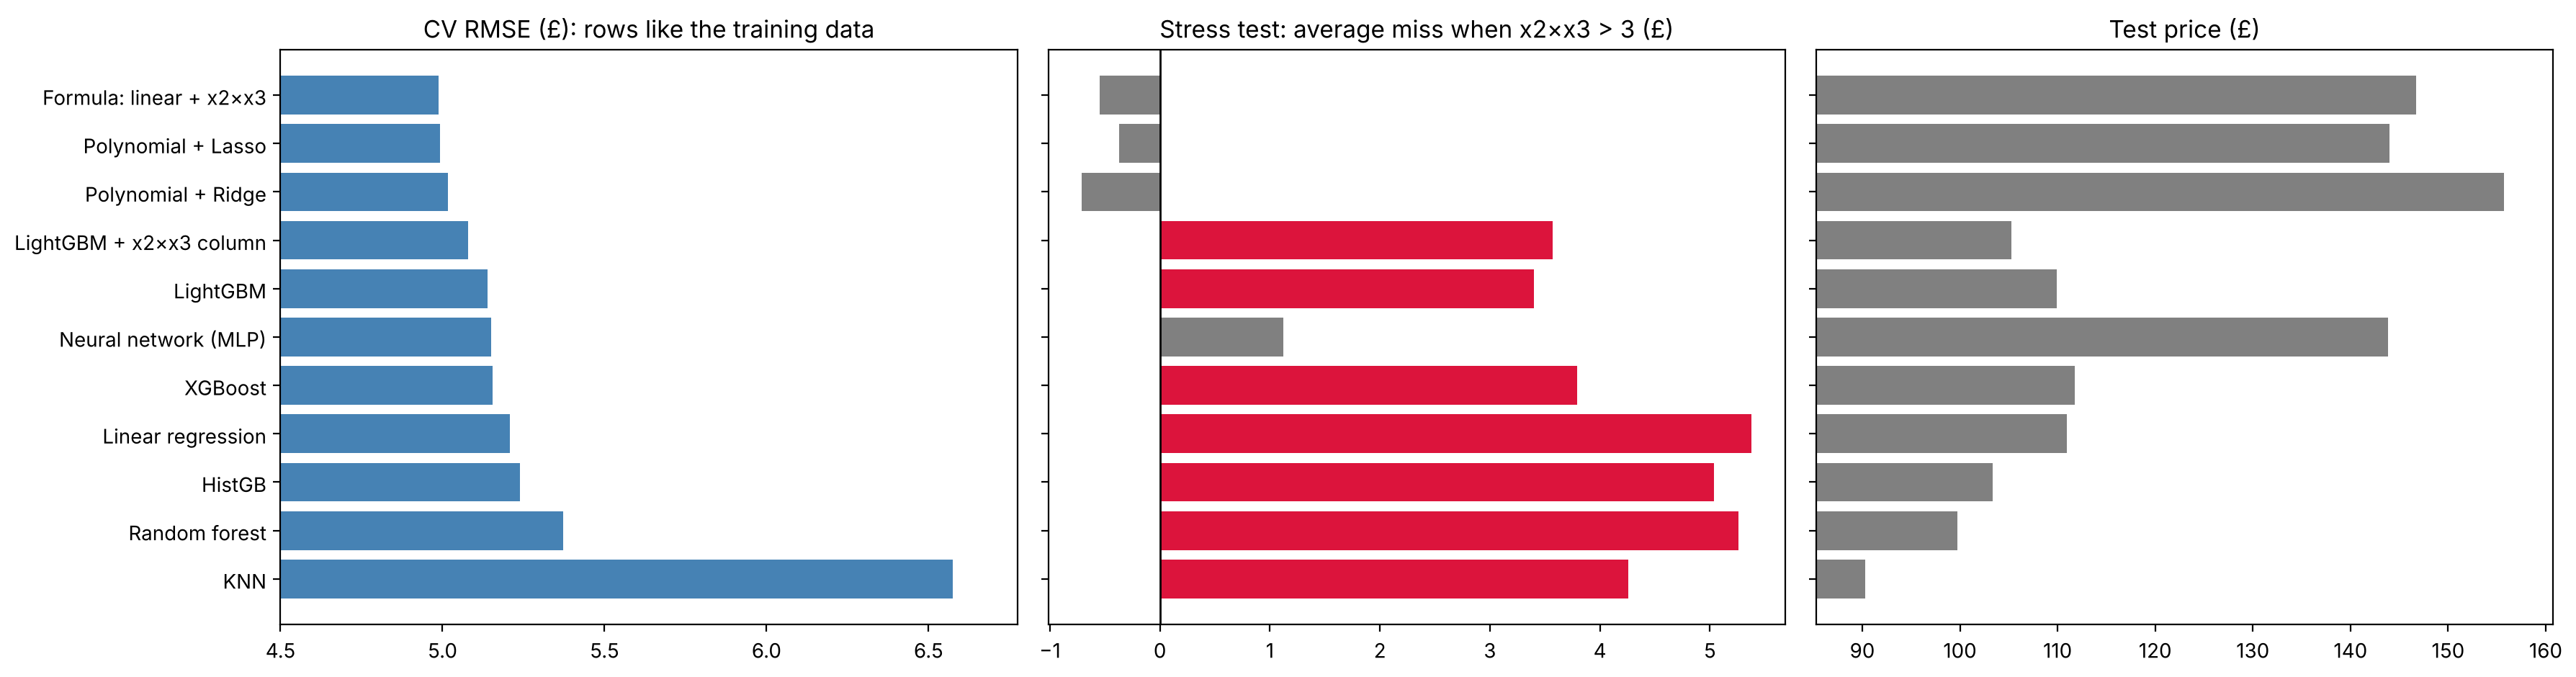

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
axes[0].barh(results["model"], results["CV RMSE (£)"], color="steelblue")
axes[0].set_xlim(4.5, results["CV RMSE (£)"].max() + 0.2)
axes[0].set_title("CV RMSE (£): rows like the training data")
axes[0].invert_yaxis()

bias = results["stress: bias when x2×x3 > 3 (£)"]
axes[1].barh(results["model"], bias, color=["crimson" if abs(v) > 1.5 else "grey" for v in bias])
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Stress test: average miss when x2×x3 > 3 (£)")

axes[2].barh(results["model"], results["test price (£)"], color="grey")
axes[2].set_xlim(results["test price (£)"].min() - 5, results["test price (£)"].max() + 5)
axes[2].set_title("Test price (£)")
plt.tight_layout()
plt.show()

**How to read Steps 4.3 and 4.4**

* **The formula** has the best CV RMSE (about £4.99, the noise level) **and** passes the stress test (bias about 0 on both sides). Test price: **about £146.7**.
* **Polynomial + Lasso** finds nearly the same formula by itself (it keeps x2 × x3 and drops most useless terms), so it gets close (about £144).
* **Polynomial + Ridge** also contains x2 × x3, but it keeps small weights on useless terms like x7², and the test row's decoys (x5–x12 ≈ ±4.5) multiply them. Its price is pushed up to about £156.
* **All tree models fail the stress test.** When x2 × x3 > 3 they underprice by about £3.40–5.30, because a tree can never predict beyond the prices it has seen. On the test row they say **about £100–112**. Even giving LightGBM the x2 × x3 column doesn't help: it still can't go past the largest value in training (about 6.9).
* **The neural network** gets about £144, but its stress test is lopsided (about +£1 on one side, −£5 on the other), so we can't trust its extrapolation.
* **Linear regression without the team effect** misses x2 × x3 entirely (about £111).

> **✅ Checkpoint.** Only the formula is both accurate and reliable when extrapolating. **Most models will price this stock far too low.**

---
# Part 5: Look inside the final model

### Step 5.1: The prediction, step by step

**What this cell does:** prices the test row with the formula from Step 3.4, shows each piece, and compares with the exact round-number recipe.

In [20]:
test_F = formula_clues(test).iloc[0]
prediction = float(formula.predict(formula_clues(test))[0])

print(f"start{'':28}{formula.intercept_:8.2f}")
for name, weight in zip(test_F.index, formula.coef_):
    print(f"+ {weight:6.2f} × {name:12s} ({test_F[name]:+7.3f})  {weight * test_F[name]:+8.2f}")
print(f"{'= prediction':33}{prediction:8.2f}")

def round_recipe(d):
    return 80 + 8 * d["m1"] - 5 * d["m2"] + 2 * d["x1"] + d["x4"] + 1.5 * d["x2"] * d["x3"]

print(f"\nRound recipe on the test row: £{float(round_recipe(test).iloc[0]):.2f}")
print(f"Round recipe on training: leftover std £{(y - round_recipe(data)).std():.3f}   (fitted formula: £{formula_leftover.std():.3f})")

start                               79.94
+   8.02 × m1           ( +1.447)    +11.61
+  -4.90 × m2           ( -1.098)     +5.38
+   2.02 × x1           ( +4.861)     +9.82
+   0.96 × x4           ( +4.735)     +4.56
+   1.50 × x2_times_x3  (+23.565)    +35.39
= prediction                       146.70

Round recipe on the test row: £146.87
Round recipe on training: leftover std £4.986   (fitted formula: £4.984)


**How to read the output**

* m1 and m2 add about £17 together, x1 about £10 and x4 about £5. **x2 × x3 adds about £35**, the biggest single piece.
* The **round recipe** (80 + 8·m1 − 5·m2 + 2·x1 + x4 + 1.5·x2·x3) fits the training data **exactly as well** as the fitted formula, and gives almost the same price.
* **Prediction: about £146.70.** That's above the highest price in training (about £124), because the test row is so extreme.

### Step 5.2: See the data and our lines

**What this cell does:** for each formula ingredient, removes the other ingredients' effects from the price and plots 3,000 random rows, with our line **extended out to the test row's value** (dashed).

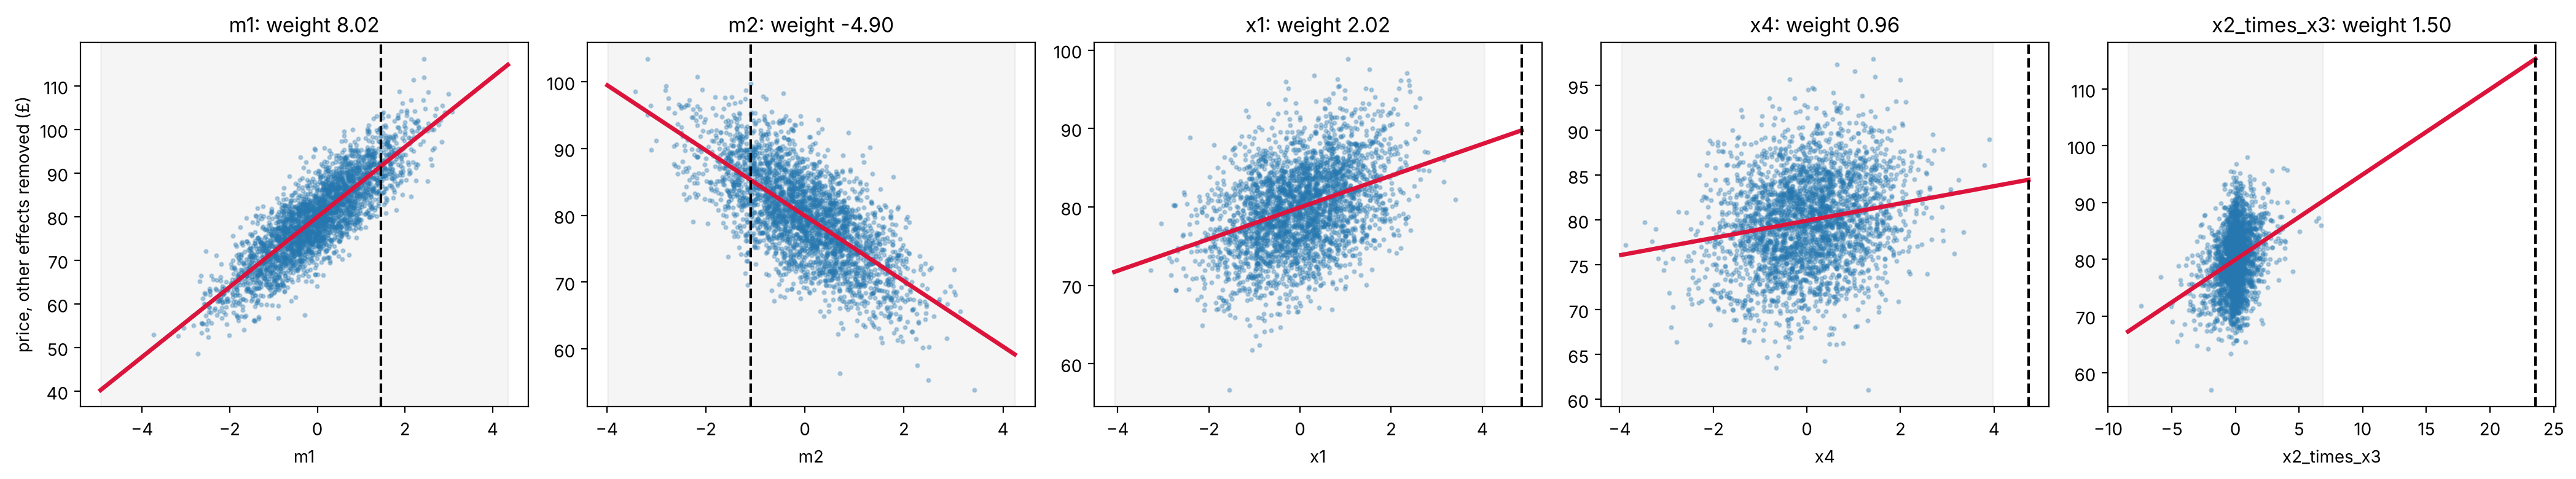

In [21]:
F_train = formula_clues(data)
sample = F_train.sample(3000, random_state=0).index
names = list(F_train.columns)

fig, axes = plt.subplots(1, 5, figsize=(21, 4))
for ax, name, weight in zip(axes, names, formula.coef_):
    others = [n for n in names if n != name]
    other_effects = (F_train[others] * [formula.coef_[names.index(n)] for n in others]).sum(axis=1)
    adjusted = y - other_effects
    ax.scatter(F_train.loc[sample, name], adjusted[sample], s=4, alpha=0.3)
    lo, hi = min(F_train[name].min(), test_F[name]), max(F_train[name].max(), test_F[name])
    line_x = np.linspace(lo, hi, 50)
    ax.plot(line_x, formula.intercept_ + weight * line_x, color="crimson", linewidth=2.5)
    ax.axvspan(F_train[name].min(), F_train[name].max(), color="grey", alpha=0.08)
    ax.axvline(test_F[name], color="black", linestyle="--")
    ax.set_title(f"{name}: weight {weight:.2f}"); ax.set_xlabel(name)
axes[0].set_ylabel("price, other effects removed (£)")
plt.tight_layout()
plt.show()

**How to read the output:** the grey area is the training range. For **m1 and m2** the test value is inside it. For **x1, x4 and especially x2 × x3** the dashed line sits **outside**, and the red line has to be **extended** to reach it. For x2 × x3 the extension is about 3.4 times longer than the data. That's the risk Part 6 measures.

> **✅ Checkpoint.** Prediction **£146.70** if the straight lines keep going.

---
# Part 6: How sure are we?

### Step 6.1: Model error (bootstrap)

**What this cell does:** retrains the formula 200 times on random rows (some twice, some not at all) and prices the test row each time.

In [22]:
rng = np.random.default_rng(0)
boot = []
for b in range(200):
    rows_b = rng.integers(0, len(data), len(data))
    model_b = LinearRegression().fit(F_train.iloc[rows_b], y.iloc[rows_b])
    boot.append(float(model_b.predict(formula_clues(test))[0]))
boot = np.array(boot)

noise = formula_leftover.std()
sigma = np.sqrt(boot.std() ** 2 + noise ** 2)
print(f"Model error (bootstrap spread): £{boot.std():.2f}")
print(f"Noise (leftover std):           £{noise:.2f}")
print(f"Total uncertainty:              £{sigma:.2f}")
print(f"68% range: £{prediction - sigma:.2f} to £{prediction + sigma:.2f}    95% range: £{prediction - 1.96 * sigma:.2f} to £{prediction + 1.96 * sigma:.2f}")

Model error (bootstrap spread): £1.09
Noise (leftover std):           £4.98
Total uncertainty:              £5.10
68% range: £141.59 to £151.80    95% range: £136.69 to £156.70


**How to read the output:** the weights are measured so precisely that the model itself moves by only about **£1**, even after multiplying by 23.6. Together with the noise (£5), the total uncertainty is about **£5.10**, **if the straight lines keep going**.

### Step 6.2: What if the team effect bends outside the data?

Inside the training range the effect is straight (Step 3.5). But a curve that **only starts to bend beyond 7** would look just as straight inside the data. So we fit a formula where the team effect follows an S-curve, `size × tanh(x2·x3 / bend)`, and try different **bend** points. A small bend means it levels off early; a huge bend means it's practically a straight line.

**What this cell does:** for each bend, fits the whole formula, checks how well it fits the training data (compared with the straight line), and prices the test row.

In [23]:
def bent_formula(X_, start, w_m1, w_m2, w_x1, w_x4, size, bend):
    m1, m2, x1, x4, team = X_
    return start + w_m1 * m1 + w_m2 * m2 + w_x1 * x1 + w_x4 * x4 + size * np.tanh(team / bend)

X_fit = (data["m1"].values, data["m2"].values, data["x1"].values, data["x4"].values, x2x3_train.values)
X_tst = (test["m1"].values, test["m2"].values, test["x1"].values, test["x4"].values, np.array([x2x3_test]))
straight_ss = (formula_leftover ** 2).sum()

bend_rows, bend_curves = [], {}
for bend in [6, 8, 11, 15, 25, 50]:
    fixed = lambda X_, s, a, b, c, d, size: bent_formula(X_, s, a, b, c, d, size, bend)
    params, _ = curve_fit(fixed, X_fit, y.values, p0=[80, 8, -5, 2, 1, 1.5 * bend], maxfev=20000)
    ss = ((y.values - fixed(X_fit, *params)) ** 2).sum()
    worse_by = len(data) / 2 * np.log(ss / straight_ss)          # how much worse than the straight line (0 = same)
    bend_curves[bend] = params[-1]
    bend_rows.append({"bend point": bend, "fit vs straight line (0 = equal, > 2 = clearly worse)": round(worse_by, 2),
                      "test price (£)": round(float(fixed(X_tst, *params)[0]), 2)})
pd.DataFrame(bend_rows)

,bend point,"fit vs straight line (0 = equal, > 2 = clearly worse)",test price (£)
0,6,1.18,120.91
1,8,-0.10,123.74
2,11,-0.41,127.74
3,15,-0.35,132.23
4,25,-0.16,139.08
5,50,-0.05,144.33


**How to read the output**

* Every bend point from about 6 upwards fits the training data **about as well as the straight line** (score below 2). The data **can't tell them apart**.
* But they give very different test prices: from about **£121** (bends early) to about **£144** (bends late), against **£146.70** for the straight line.

**What this cell does:** draws the team effect for the straight line and for three bend points, with the training data and the test row.

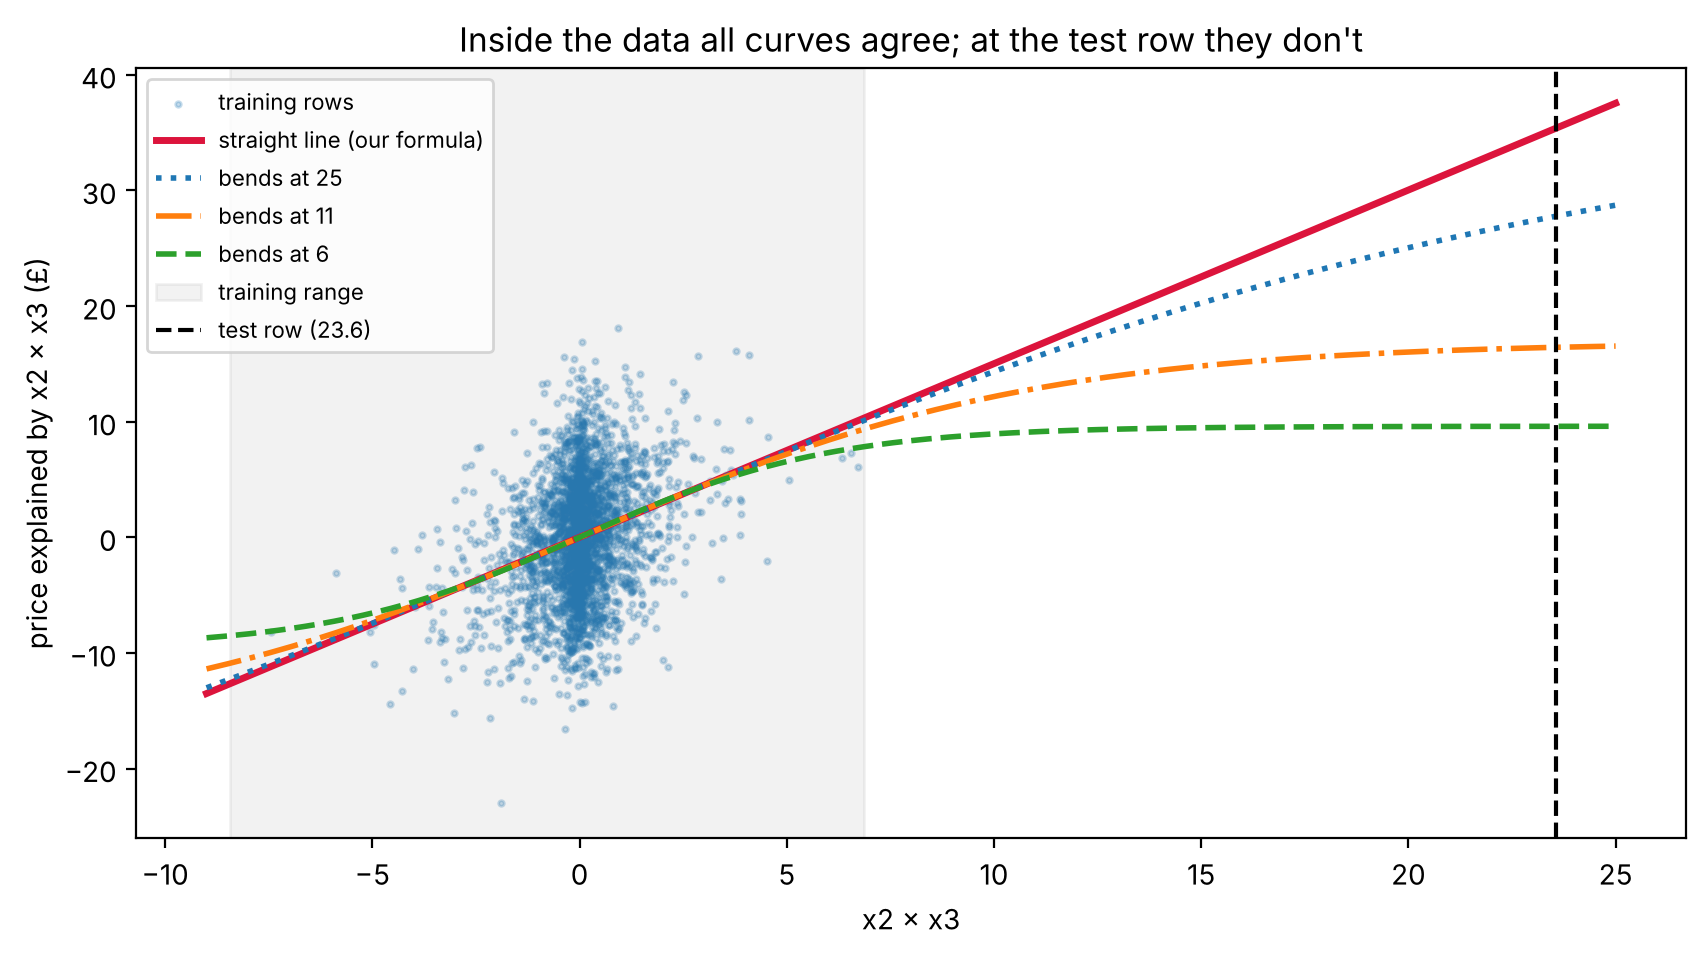

In [24]:
other_parts = formula.predict(F_train) - formula.coef_[-1] * x2x3_train            # start + everything except the team effect
team_part = y - other_parts                                                         # price explained by x2 × x3 (plus noise)
plt.figure(figsize=(10, 5))
plt.scatter(x2x3_train[sample], team_part[sample], s=4, alpha=0.25, label="training rows")
line_x = np.linspace(-9, 25, 200)
plt.plot(line_x, formula.coef_[-1] * line_x, color="crimson", linewidth=2.5, label="straight line (our formula)")
for bend, style in [(25, ":"), (11, "-."), (6, "--")]:
    plt.plot(line_x, bend_curves[bend] * np.tanh(line_x / bend), linestyle=style, linewidth=2, label=f"bends at {bend}")
plt.axvspan(x2x3_train.min(), x2x3_train.max(), color="grey", alpha=0.1, label="training range")
plt.axvline(x2x3_test, color="black", linestyle="--", label=f"test row ({x2x3_test:.1f})")
plt.xlabel("x2 × x3"); plt.ylabel("price explained by x2 × x3 (£)")
plt.title("Inside the data all curves agree; at the test row they don't")
plt.legend(fontsize=8, loc="upper left")
plt.show()

**How to read the output:** inside the grey area, all the lines lie on top of each other. Out at the test row (23.6) they fan out by more than £25. **No model can know which one is true from this data.**

Why we still believe the straight line:
1. The weights come out as **round numbers** (8, −5, 2, 1, 1.5). A hidden S-curve wouldn't produce that.
2. The **stress test** (Part 4): trained on central rows, the straight formula predicted the outer rows **without bias**.
3. Every shape that bends **inside** the data fits worse (Step 3.5).

### Step 6.3: All the scenarios together

**What this cell does:** collects the price under every scenario, including what other teams are likely to get.

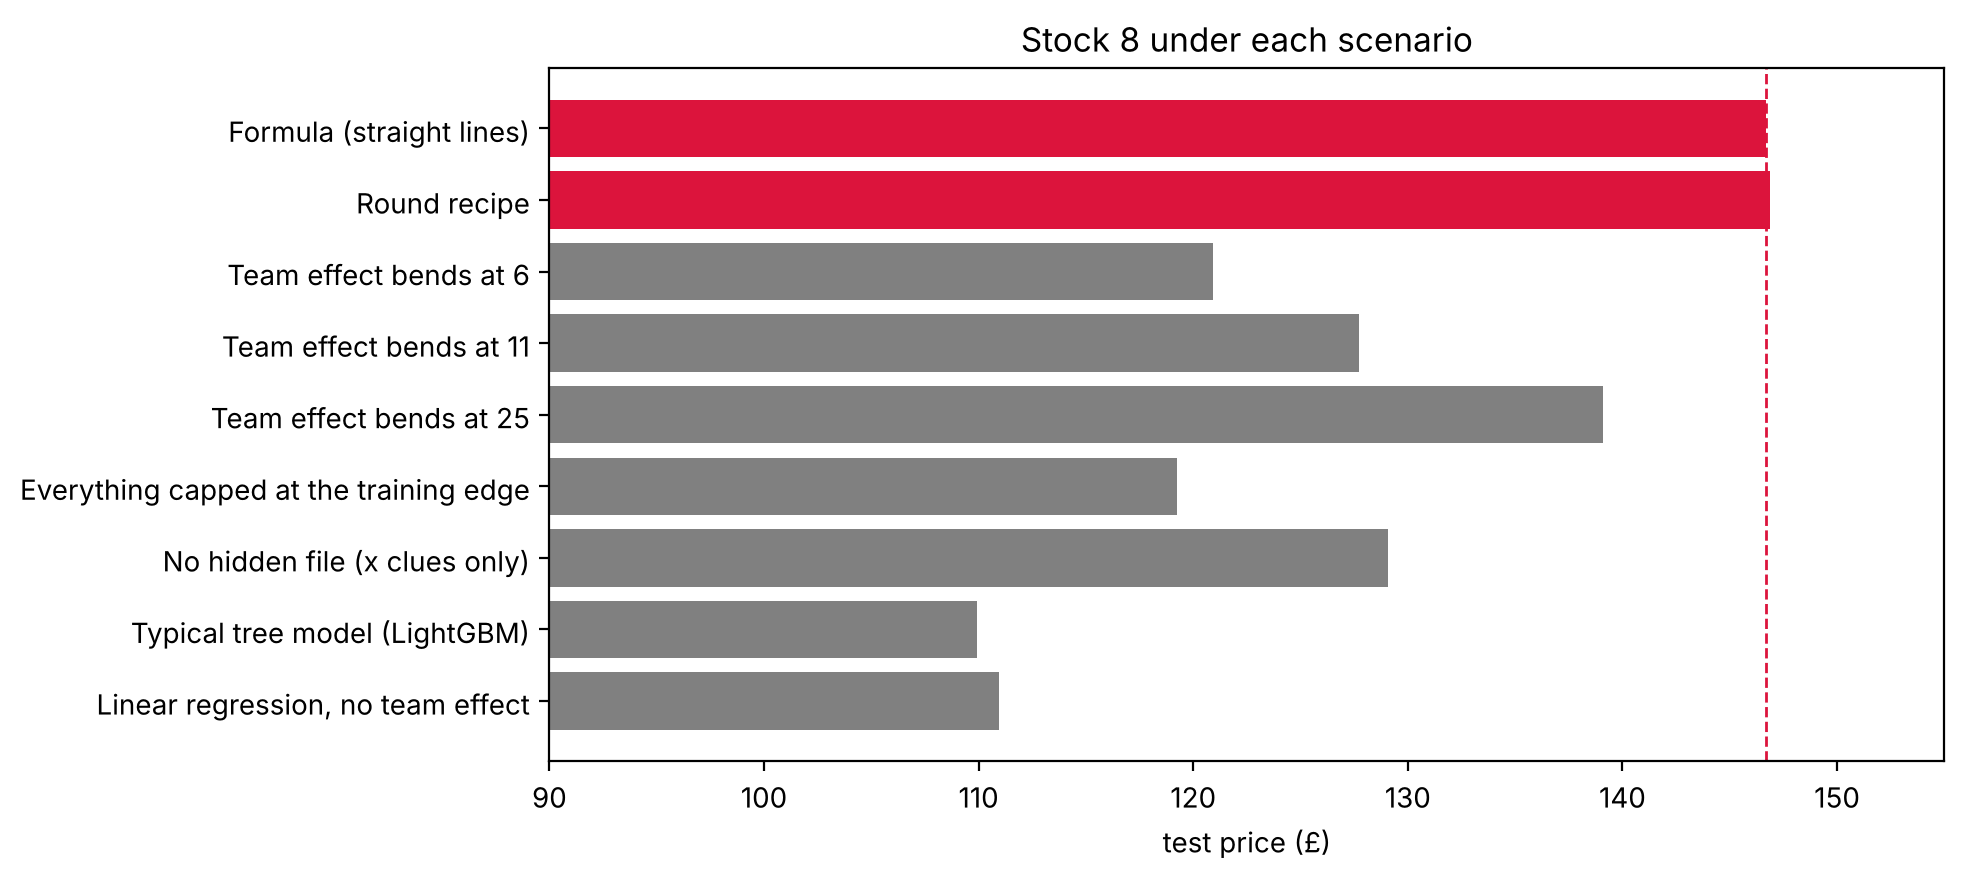

,test price (£)
Formula (straight lines),146.70
Round recipe,146.87
Team effect bends at 6,120.91
Team effect bends at 11,127.74
Team effect bends at 25,139.08
Everything capped at the training edge,119.24
No hidden file (x clues only),129.07
Typical tree model (LightGBM),109.91
"Linear regression, no team effect",110.93


In [25]:
capped = formula_clues(test).copy()
for name in ["x1", "x4", "x2_times_x3"]:
    capped[name] = capped[name].clip(F_train[name].min(), F_train[name].max())     # stop at the training edge
x_only_all = LinearRegression().fit(F_train[["x1", "x4", "x2_times_x3"]], y)        # no hidden file

scenarios = pd.Series({
    "Formula (straight lines)": prediction,
    "Round recipe": float(round_recipe(test).iloc[0]),
    **{f"Team effect bends at {r['bend point']}": r["test price (£)"] for r in bend_rows if r["bend point"] in [25, 11, 6]},
    "Everything capped at the training edge": float(formula.predict(capped)[0]),
    "No hidden file (x clues only)": float(x_only_all.predict(formula_clues(test)[["x1", "x4", "x2_times_x3"]])[0]),
    "Typical tree model (LightGBM)": float(results.set_index("model").loc["LightGBM", "test price (£)"]),
    "Linear regression, no team effect": float(results.set_index("model").loc["Linear regression", "test price (£)"]),
}).round(2)

plt.figure(figsize=(9, 4.5))
plt.barh(scenarios.index, scenarios.values, color=["crimson" if i < 2 else "grey" for i in range(len(scenarios))])
plt.axvline(prediction, color="crimson", linestyle="--", linewidth=1)
plt.gca().invert_yaxis()
plt.xlim(90, 155); plt.xlabel("test price (£)")
plt.title("Stock 8 under each scenario")
plt.show()
scenarios.to_frame("test price (£)")

**How to read the output:** our central estimate is **£146.70**. If the team effect bends beyond the data, the price could be about £121–144. Teams that miss the hidden file, the team effect, or use tree models will say about **£100–130**.

> **✅ Checkpoint.** Price **£146.70 ± £5.10** if the formula holds (our best judgement). The real risk is a bend beyond the data (down to about £121), not the noise.

---
# Part 7: Make a quote and a trading plan

### Step 7.1: Quote options

**What this cell does:** prints quotes for 1, 2 and 3 std of the total uncertainty.

In [26]:
centre = prediction
for k in [1, 2, 3]:
    print(f"±{k} std:  bid £{centre - k * sigma:.2f}   ask £{centre + k * sigma:.2f}")

±1 std:  bid £141.59   ask £151.80
±2 std:  bid £136.49   ask £156.90
±3 std:  bid £131.39   ask £162.00


### Step 7.2: Market maker or trader?

* **Most teams will price this stock at about £100–130** (trees, no team effect, no hidden file). If one of them is market maker, its ask will be far below our centre, and we **buy big**.
* **If we're market maker**, those same teams will **sell to us in size** (they think we're too high). If the formula holds, we profit. If the team effect bends early, we lose about £10–20 per share on a large position.
* **Buying from a low market maker is safer**: buying at about £110 is profitable in **every** scenario, even the early bend (about £121).

**Suggestion:** stay a trader. Quote **±2 std** or wider so you don't win the seat, and buy from a low market maker.

### Step 7.3: Trading plan

You buy at the market maker's **ask** and sell at its **bid**. Compare them with our centre (**£146.70**):

| Market maker's prices | What we do | Size |
|---|---|---|
| **Ask below about £121** (cheaper than even the early-bend scenario) | **Buy** | **Maximum** |
| Ask between about £121 and £136.50 (more than 2 std under) | Buy | Big |
| Ask between about £136.50 and £146.70 | Buy | Small |
| Bid between about £146.70 and £156.90 | Little edge | Minimum, or sell small |
| Bid above about £156.90 (more than 2 std over) | Sell | Medium (the bend risk only pushes the price down, so selling is safer than usual) |
| **Bid above about £162** (more than 3 std over) | **Sell** | **Big** |

**Likely scenarios:**
* Market maker used **trees, or a line without the team effect** (mid about £100–112) → **buy the maximum**.
* Market maker **didn't use the hidden file** (mid about £129) → **buy big**.
* Market maker found the formula (mid about £146–147) → no edge, trade the minimum.

---

### Lessons so far

| Stock | Trap | What we did |
|---|---|---|
| 1 | None (warm-up) | Linear regression, quote ±1–2 std |
| 2 | Few rows, extreme test row | Wide quote (±£15), stay a trader |
| 3 | Out-of-range **decoy** clue | Checked it has no effect, removed it |
| 4 | Missing near-copy of the price, noise that depends on x5 | Dropped x7, measured the noise where the test row lives |
| 5 | Missing value + rare sector | Flag for missing x3, a separate x1 weight per sector |
| 7 | Prices in pence, a team effect, jumpy noise | Cleaned prices, found x5 × x6, used real miss ranges |
| 8 | **Hidden file, team effect, extreme test row** | Joined m1/m2, found x2 × x3, stress-tested extrapolation, priced the bend risk |

> **✅ Final checkpoint.** Stock 8 price **£146.70 ± £5.10**. Formula: **80 + 8·m1 − 5·m2 + 2·x1 + x4 + 1.5·x2·x3**. Downside risk: about £121 if the team effect bends beyond the data. Most other teams will be far too low, so **buy from them**.